# Bilayer Wigner Crystal Point Defects

**Goal.** Reproduce three representative point-defect configurations from Z. Zhuang and I. Esterlis, *"Defect liquids in a weakly imbalanced bilayer Wigner crystal,"* Phys. Rev. B **111**, 205122 (2025), [doi:10.1103/PhysRevB.111.205122](https://doi.org/10.1103/PhysRevB.111.205122) — a vacancy defect (VD), an interstitial defect (ID), and an interstitial-vacancy defect (IV) — using gradient-based optimization with no defect geometry assumed in advance, and compare them to the paper's own Fig. 5.

**What this tutorial covers:**
- Building a periodic bilayer supercell that holds exactly one point defect (vacancy, interstitial, or interstitial-vacancy), following the paper's supercell construction but starting from phase III at every $\eta$
- Relaxing the cell shape and every electron position simultaneously with JAX autodiff and `optax`, using `ezwald.bilayer_sum.EwaldSumSlab` for the energy
- Recentering a periodic defect for display — the optimizer has no reason to keep it in the middle of the plotted cell, since the energy is invariant under a uniform translation of the whole pattern

**Requirements:** `ezwald`, `jax`, `optax`, `numpy`, `scipy`, `matplotlib`. Runs in about a minute on CPU.

## Background

A vacancy defect (VD) removes one electron from a layer; an interstitial defect (ID) adds one; an interstitial-vacancy defect (IV) moves one electron from one layer to the same in-plane position in the other.

Zhuang and Esterlis compute each defect's energy with a supercell commensurate with the defect-free bilayer crystal at the given $\eta$: if the perfect lattice has primitive vectors $\mathbf a_1,\mathbf a_2$, the supercell is built from $\mathbf c_1=L\mathbf a_1,\ \mathbf c_2=L\mathbf a_2$ for an integer $L$, holding exactly one defect per supercell. Here the starting lattice is instead always the staggered-square phase III lattice, regardless of which phase is the ground state at a given $\eta$. The defect is inserted at the supercell's center and the full structure — cell shape *and* every electron position — is relaxed by minimizing the bilayer Ewald energy, so the relaxed supercell need not be $L\mathbf a_1,\ L\mathbf a_2$ of the final lattice. Here $n=1$ is the total areal density ($n_s=n/2$ per layer), $e=1$, and $\eta=d\sqrt{n_s}$ is the dimensionless interlayer parameter, with $d$ the interlayer distance.

In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import optax
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
from ezwald import bilayer_sum, geometry as geo

np.set_printoptions(precision=6, suppress=True)

n_total = 1.0
n_s = n_total / 2.0
A_PRIM = np.sqrt(1.0 / n_s)  # primitive side of the phase III (staggered square) reference cell

def eta_to_d(eta):
    return eta / np.sqrt(n_s)

## 1. Building a supercell with one defect

The reference lattice is the ideal $L\times L$ phase III supercell: layer A sites on a square grid of side `A_PRIM`, layer B shifted by the interlayer vector $\mathbf c=(\mathbf a_1+\mathbf a_2)/2$. The defect is inserted at the site nearest the supercell's geometric center:

- **VD**: remove the layer-A site nearest the center.
- **ID**: add an extra layer-A electron at the interstitial site $\mathbf r_{\rm center}+\mathbf c$.
- **IV**: move that center site from layer A to the same in-plane position in layer B.

In the code, layer A is called `up` and layer B `down`: `EwaldSumSlab.energy` takes the positions of the top layer (`np` electrons) first and then those of the bottom layer (`nd` electrons), and layer A is passed as the top layer.

In [2]:
def build_population(L, pop):
    '''Ideal L x L phase III supercell with one defect of type pop, Cartesian positions.

    Returns (cell0, positions, n_up, n_down).
    '''
    cell0 = np.diag([L * A_PRIM, L * A_PRIM])
    ii, jj = np.meshgrid(np.arange(L), np.arange(L))
    RA = np.stack([ii.ravel(), jj.ravel()], axis=-1) * A_PRIM
    c = np.array([A_PRIM / 2, A_PRIM / 2])
    RB = RA + c
    center = cell0.sum(axis=0) / 2
    i0 = int(np.argmin(np.linalg.norm(RA - center, axis=1)))
    site = RA[i0].copy()

    if pop == "VD":
        A = np.delete(RA, i0, axis=0)
        B = RB
    elif pop == "ID":
        A = np.vstack([RA, site + c])
        B = RB
    elif pop == "IV":
        A = np.delete(RA, i0, axis=0)
        B = np.vstack([RB, site])  # the added electron is the last one in layer B
    else:
        raise ValueError(pop)

    return cell0, np.concatenate([A, B], axis=0), len(A), len(B)

## 2. Cell + position optimizer

The oblique cell (fixed area, free side $a$ and angle $\theta$) and all electron positions are relaxed together by gradient descent, with no defect geometry or lattice symmetry assumed. Three technical points make this differentiable and numerically stable while the cell changes shape:

1. **Fixed G-point indices.** `EwaldSumSlab`'s default G-vector selection can't be differentiated through, so integer G-indices are precomputed once from the reference cell and mapped through the *current* reciprocal vectors at every step.
2. **Fixed Ewald `alpha`.** The Ewald splitting parameter is also taken once from the reference cell rather than recomputed from the changing cell, which keeps the energy stable as the cell deforms.
3. **Symmetry-breaking jitter.** In the perfectly symmetric starting lattice the gradient with respect to the cell shape is zero by symmetry, and for the ID, whose added electron starts directly above a layer-B electron, the gradient is undefined (NaN). Every starting position therefore gets a small random displacement.

In [3]:
def setup(L, eta):
    d = eta_to_d(eta)
    area = 2.0 * L * L / n_total
    cell0 = np.diag([L * A_PRIM, L * A_PRIM])
    trial = bilayer_sum.EwaldSumSlab(cell0, float(d), disp_fn_mode='general', n_lat=1)
    recvec0 = np.asarray(geo.calc_recvec(jnp.asarray(cell0)))
    gidx = jnp.asarray(np.array(np.round(trial.gpoints @ np.linalg.inv(recvec0)), dtype=int))
    return d, area, gidx, float(trial.alpha)


def make_loss(d, alpha, gidx, n_up, n_down, area, aref):
    lo, hi = 0.55 * aref, 1.8 * aref
    th_lo, th_hi = jnp.deg2rad(40.0), jnp.deg2rad(140.0)
    charge = -jnp.ones(n_up + n_down)

    def unpack(p):
        a = lo + (hi - lo) * jax.nn.sigmoid(p['raw_a'])
        th = th_lo + (th_hi - th_lo) * jax.nn.sigmoid(p['raw_theta'])
        return a, th

    def cell_from(a, th):
        b = area / (a * jnp.sin(th))
        return jnp.stack([jnp.stack([a, 0.0 * a]),
                          jnp.stack([b * jnp.cos(th), b * jnp.sin(th)])])

    def loss(p):
        a, th = unpack(p)
        cell = cell_from(a, th)
        gpoints = gidx @ geo.calc_recvec(cell)
        bew = bilayer_sum.EwaldSumSlab(cell, d, disp_fn_mode='general', gpoints=gpoints,
                                       alpha=alpha, n_lat=1)
        pos = p['pos_frac'] @ cell
        return bew.energy(charge, pos, np=n_up, nd=n_down) / (n_up + n_down)

    return loss, unpack, cell_from


def optimize_defect(L, eta, pop, nstep=1200, lr=0.01, jitter=0.02, seed=0):
    '''Relax cell (a, theta) and all electron positions for one defect population. Returns a dict
    with the energy per particle, the optimized cell and its (a, theta), the Cartesian positions
    of layer A (pos_up) and layer B (pos_down), and the number of electrons in each layer.'''
    d, area, gidx, alpha = setup(L, eta)
    cell0_pop, R_cart, n_up, n_down = build_population(L, pop)
    aref = np.sqrt(area)
    frac0 = R_cart @ np.linalg.inv(cell0_pop)
    frac0 = frac0 + jitter * np.random.default_rng(seed).standard_normal(frac0.shape)

    loss, unpack, cell_from = make_loss(d, alpha, gidx, n_up, n_down, area, aref)
    sig_inv = lambda y: np.log(y / (1 - y))
    lo, hi = 0.55 * aref, 1.8 * aref
    p = {'raw_a': jnp.array(sig_inv((aref - lo) / (hi - lo))),
         'raw_theta': jnp.array(sig_inv((np.radians(90) - np.radians(40)) /
                                        (np.radians(140) - np.radians(40)))),
         'pos_frac': jnp.array(frac0)}

    vg = jax.jit(jax.value_and_grad(loss))
    opt = optax.chain(optax.clip(1.0), optax.adam(optax.exponential_decay(lr, 200, 0.5)))
    state = opt.init(p)
    for _ in range(nstep):
        _, g = vg(p)
        updates, state = opt.update(g, state, p)
        p = optax.apply_updates(p, updates)

    a, th = unpack(p)
    cell = np.asarray(cell_from(a, th))
    pos = np.asarray(p['pos_frac']) @ cell
    return {'E': float(loss(p)), 'theta_deg': float(np.degrees(th)), 'a': float(a),
            'cell': cell, 'pos_up': pos[:n_up], 'pos_down': pos[n_up:],
            'n_up': n_up, 'n_down': n_down, 'pop': pop}

## 3. Centering the defect for display

Nothing in the optimization anchors the pattern to a particular location: the Coulomb energy is invariant under a uniform translation of every electron (in both layers) by the same vector, so gradient descent is free to let the whole relaxed structure drift across periodic images relative to where it started. `recenter` undoes that drift for plotting only (it has no effect on the energy or the relaxed structure itself) by shifting every position, in fractional coordinates of the optimized cell, so the defect sits at the cell's center.

The defect is located from the relaxed structure with `find_defect_sites`: in the hexagonal and rhombic layers of the VD and ID structures, every electron of a perfect layer has six nearest neighbors, so the electrons of layer A with any other number mark the defect. This is needed because the lattice can rearrange substantially during relaxation, so the electrons next to the defect at the start are not necessarily next to it at the end. The test does not apply to the square layers of the IV structure (a perfect square layer has no unique set of six neighbors), whose added layer-B electron stays at the center of the defect at the $\eta$ used here and is used to locate it instead.

A single missing or added electron in a dense lattice rarely stands out by eye once it has relaxed — the surrounding sites redistribute the strain rather than leaving one obvious large gap, which is why the paper itself outlines the defect motif in Fig. 5. `plot_defect` does the same with a dashed circle at the cell's center. Electrons whose markers would cross the cell boundary are left out of the plot (11 to 16 of the roughly 128 electrons here), so the outermost rows of a plot may be incomplete; this is a display choice only, and those electrons remain part of the relaxed structure and its energy.

In [4]:
def find_defect_sites(cell, pos):
    '''Indices of the electrons in `pos` without six nearest neighbors, counted with a periodic
    Delaunay triangulation of that layer. Returns an anchor = (layer, indices) for `recenter`.'''
    n = len(pos)
    shifts = np.array([[i, j] for i in (-1, 0, 1) for j in (-1, 0, 1)]) @ cell
    tiled = np.concatenate([pos + s for s in shifts])  # shift (0, 0) is copy 4
    neighbors = [set() for _ in tiled]
    for simplex in Delaunay(tiled).simplices:
        for i in simplex:
            neighbors[i].update(simplex)
    n_neighbors = np.array([len(neighbors[4 * n + i]) - 1 for i in range(n)])
    return ("up", np.where(n_neighbors != 6)[0].tolist())


def recenter(cell, pos_up, pos_down, anchor):
    '''Shift the whole periodic configuration so the defect sits at the center of the plotted
    cell. anchor = (layer, indices): the defect's position is the mean of pos_up/pos_down at
    those indices.

    The naive approach — wrap every position into fractional coordinates in [0, 1), independently
    — can tear the defect apart: if its anchor points straddle the periodic boundary after
    optimization, each one wraps to a different edge of the cell even though their *unwrapped*
    centroid is exactly where we want it. We first pull the anchor points onto the same periodic
    image (minimum-image convention relative to the first one) so their centroid is meaningful,
    shift by that centroid, and only then wrap every electron into [0, 1).
    '''
    layer, idx = anchor
    inv_cell = np.linalg.inv(cell)
    anchor_frac = (pos_up if layer == "up" else pos_down)[idx] @ inv_cell
    anchor_frac = anchor_frac[0] + (anchor_frac - anchor_frac[0] + 0.5) % 1.0 - 0.5  # minimum image
    shift = 0.5 - anchor_frac.mean(axis=0)

    def shift_layer(pos):
        frac = (pos @ inv_cell + shift) % 1.0
        assert np.all((frac >= 0.0) & (frac < 1.0))  # every electron lands inside the cell
        return frac @ cell

    return shift_layer(pos_up), shift_layer(pos_down)


def inside_cell(pos, cell, margin=0.01):
    '''Electrons whose plotted markers fit fully inside the cell: those at least `margin`
    (fractional) away from every edge.'''
    frac = pos @ np.linalg.inv(cell)
    return pos[np.all((frac >= margin) & (frac <= 1 - margin), axis=1)]


def plot_defect(result, title, L):
    '''Plot one relaxed supercell with its defect at the center, marked by a dashed circle.'''
    cell = result['cell']
    # IV keeps the phase III square layers, where the six-neighbor test does not apply; its added
    # electron stays at the center of the defect at eta=0.60, so that electron is the anchor instead.
    if result['pop'] == "IV":
        anchor = ("down", [result['n_down'] - 1])
    else:
        anchor = find_defect_sites(cell, result['pos_up'])
    pos_up, pos_down = recenter(cell, result['pos_up'], result['pos_down'], anchor)
    pos_up = inside_cell(pos_up, cell)
    pos_down = inside_cell(pos_down, cell)

    fig, ax = plt.subplots(figsize=(7.0, 7.0))
    (h_B,) = ax.plot(*pos_down.T, ls="", marker="o", ms=6, mfc="tab:blue", mec="none", label="layer B")
    (h_A,) = ax.plot(*pos_up.T, ls="", marker="o", ms=6, mfc="tab:red", mec="none", label="layer A")
    corners = np.array([[0, 0], cell[0], cell[0] + cell[1], cell[1], [0, 0]])
    ax.plot(corners[:, 0], corners[:, 1], color="gray", lw=1)

    # recenter() puts the defect at the cell's center, but a single missing or added electron
    # rarely stands out by eye in a dense lattice — the paper itself outlines the defect motif
    # in Fig. 5 for the same reason. We do the same here with a dashed circle.
    center = cell.sum(axis=0) / 2
    radius = 1.8 * result['a'] / L
    ax.add_patch(plt.Circle(center, radius, fill=False, ls="--", color="black", lw=1.4, alpha=0.6))

    pad = 0.08 * max(np.abs(cell).max(), 1.0)
    ax.set_xlim(corners[:, 0].min() - pad, corners[:, 0].max() + pad)
    ax.set_ylim(corners[:, 1].min() - pad, corners[:, 1].max() + pad)
    ax.set_aspect(1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=10)
    ax.legend(handles=[h_A, h_B], frameon=False, loc="upper right", fontsize=8)
    fig.tight_layout()
    plt.show()

## 4. Vacancy defect (VD) at $\eta=1.00$

Compare against Zhuang and Esterlis, Fig. 5(b), rightmost panel ($\eta=1.00$, phase V). The paper notes that in phase V the VD is not simply a stack of a perfect layer with the two-fold-symmetric single-layer vacancy (SLVD-2); instead, it is composed of a vacancy defect with three-fold symmetry (SLVD-3-like), since the two layers have different rotational symmetries in phase V.

The relaxed electrons form a phase V lattice, but the relaxed cell ($\theta\approx82°$) is not the paper's $L\mathbf a_1,\ L\mathbf a_2$ supercell: it is the equal-area phase V supercell $8\mathbf a_1,\ -3\mathbf a_1+8\mathbf a_2$, where $\mathbf a_1,\mathbf a_2$ are the phase V primitive vectors, reached from the phase III starting cell. Its sides have lengths $7a_V$ and $8a_V$, where $a_V$ is the phase V lattice spacing, at an angle of $\arccos(1/7)\approx81.8°$; the cell printed below the plot confirms this.

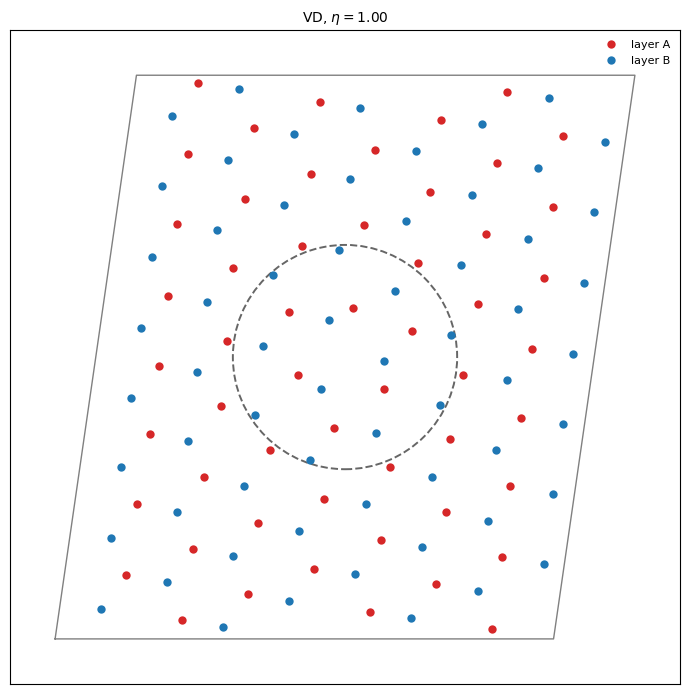

theta = 81.79 deg   |c1| = 7.001 a_V   |c2| = 7.999 a_V


In [5]:
L = 8
result_VD = optimize_defect(L, eta=1.00, pop="VD")
plot_defect(result_VD, r"VD, $\eta=1.00$", L)

a_V = np.sqrt(2 / (np.sqrt(3) * n_s))  # phase V lattice spacing at this density
c1, c2 = result_VD['cell']
print(f"theta = {result_VD['theta_deg']:.2f} deg   |c1| = {np.linalg.norm(c1) / a_V:.3f} a_V   "
      f"|c2| = {np.linalg.norm(c2) / a_V:.3f} a_V")

## 5. Interstitial defect (ID) at $\eta=0.70$

Compare against Zhuang and Esterlis, Fig. 5(a), sixth panel ($\eta=0.70$, phase IV). The paper reports that the ID's shape continuously changes with increasing $\eta$ in this range, en route to a first-order transition to phase V.

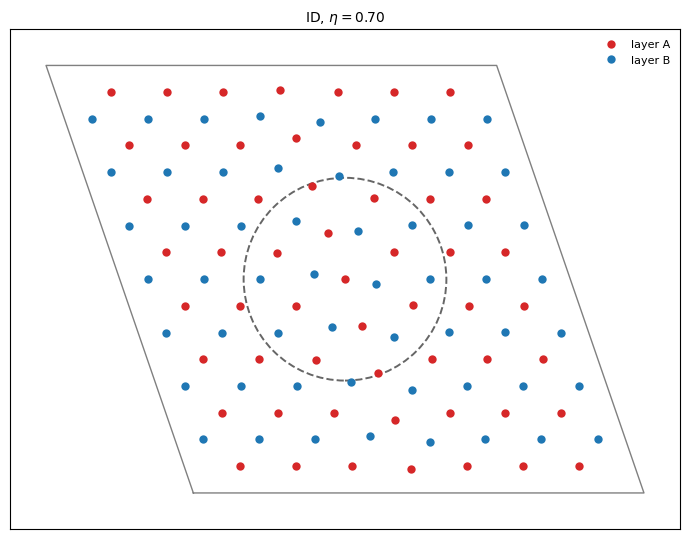

In [6]:
result_ID = optimize_defect(L, eta=0.70, pop="ID")
plot_defect(result_ID, r"ID, $\eta=0.70$", L)

## 6. Interstitial-vacancy defect (IV) at $\eta=0.60$

Compare against Zhuang and Esterlis, Fig. 5(c), fifth panel ($\eta=0.60$, phase III). Here layer A holds a vacancy and layer B an interstitial, so the two layers hold $L^2-1$ and $L^2+1$ electrons. The paper reports that around $\eta\approx0.59$ a phonon mode softens, rotating the defect about its center. The relaxed structure shows the same motif: the added layer-B electron at the center, its four layer-B neighbors rotated together away from the lattice axes, and a layer-A electron on each side of the square they form. Of the $\eta$ values tested, this is the clearest match to Fig. 5(c); at $\eta=0.75$, in phase V, the relaxations here did not clearly reproduce the paper's triangular motif.

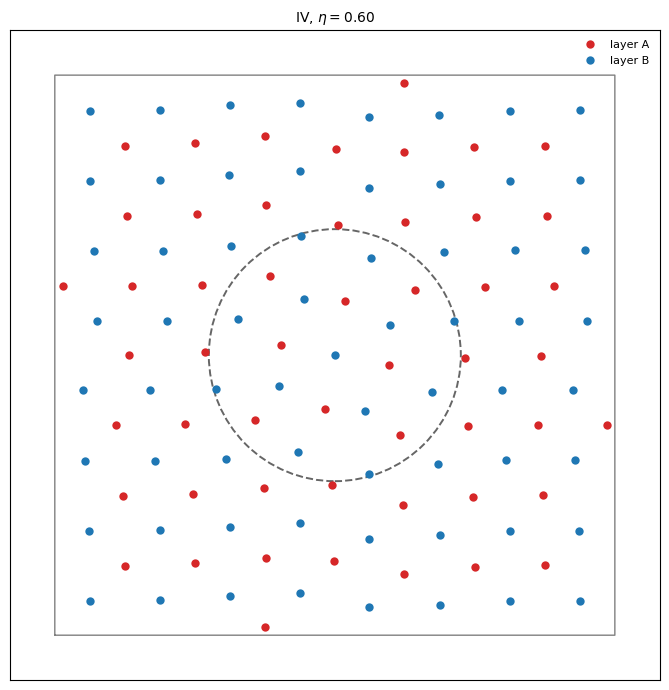

In [7]:
result_IV = optimize_defect(L, eta=0.60, pop="IV")
plot_defect(result_IV, r"IV, $\eta=0.60$", L)

## Conclusion

Starting from a phase III lattice with one defect at the supercell's center (one missing electron, one extra electron, or one electron moved between layers) and a value of $\eta$, a general cell-and-position optimizer relaxes each configuration into a point defect that qualitatively resembles the representative configurations reported in Fig. 5 of Zhuang and Esterlis. This is a visual comparison at $L=8$, a smaller supercell than the paper's largest, $L=27$. No defect geometry, lattice symmetry, or phase is imposed on the final structure, although the starting lattice can influence which structure is found. Recentering is purely a display step: it has no effect on the relaxed structure or its energy, only on which periodic image of each electron is drawn.